In [1]:
import pandas as pd

df = pd.read_excel(r"C:\KULIAH\UPN\TUGAS WOK\Semester 5 bos\ADW\Inflasi Kota Surabaya Tahun 2008-2024.xlsx")

df['Tahun'] = df['Tahun'].ffill()
df['Tahun'] = df['Tahun'].astype(int)

df


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\Sulaiman\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "c:\Users\Sulaiman\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "c:\Users\Sulaiman\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io_loop.start()
  File "c:\Users\Sulaiman\anaconda3\L

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\Sulaiman\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "c:\Users\Sulaiman\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "c:\Users\Sulaiman\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io_loop.start()
  File "c:\Users\Sulaiman\anaconda3\L

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



,Tahun,Bulan,Bulanan,Kumulatif,YoY
0,2008,Januari,1.38,1.38,-
1,2008,Februari,0.65,2.04,-
2,2008,Maret,1.52,3.59,8.90
3,2008,April,0.79,4.41,9.17
4,2008,Mei,1.39,5.87,10.09
...,...,...,...,...,...
199,2024,Agustus,-0.08,0.75,2.04
200,2024,September,-0.11,0.63,1.64
201,2024,Oktober,0.11,0.75,1.53
202,2024,November,0.19,0.94,1.31


In [2]:
df.dtypes

Tahun          int64
Bulan         object
Bulanan      float64
Kumulatif    float64
YoY           object
dtype: object

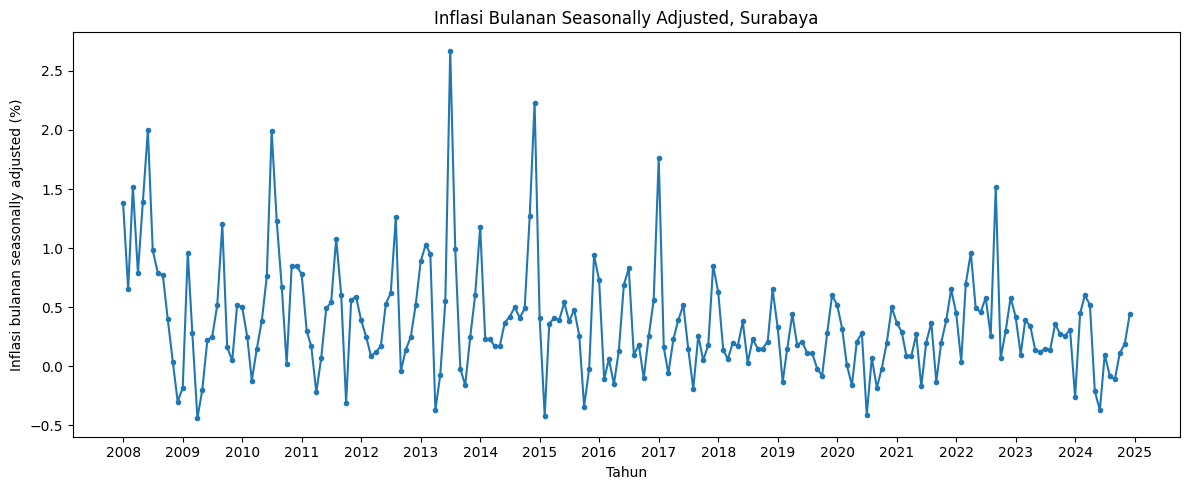

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

bulan_ke = {
    'januari': 1, 'februari': 2, 'maret': 3, 'april': 4,
    'mei': 5, 'juni': 6, 'juli': 7, 'agustus': 8,
    'september': 9, 'oktober': 10, 'november': 11, 'desember': 12
}

tahun = pd.to_numeric(df['Tahun'], errors='raise').astype(int)
bulan = df['Bulan'].astype(str).str.strip().str.lower().map(bulan_ke)

if bulan.isna().any():
    raise ValueError(f"Unrecognized month names: {df.loc[bulan.isna(), 'Bulan'].unique()}")

df_plot = df.copy()
df_plot['Tanggal'] = pd.to_datetime({
    'year': tahun,
    'month': bulan,
    'day': 1
})
df_plot = df_plot.sort_values('Tanggal')

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_plot['Tanggal'], df_plot['Bulanan'], marker='o', markersize=3)

ax.set_xlabel('Tahun')
ax.set_ylabel('Inflasi bulanan seasonally adjusted (%)')
ax.set_title('Inflasi Bulanan Seasonally Adjusted, Surabaya')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.tight_layout()
plt.show()

In [4]:
from statsmodels.tsa.stattools import adfuller, kpss

series = (
    df_plot.sort_values('Tanggal')
    .set_index('Tanggal')['Bulanan']
    .astype(float)
)

if series.isna().any():
    raise ValueError("Bulanan contains missing values; handle those before testing.")

adf_result = adfuller(series, regression='c', autolag='AIC')
kpss_result = kpss(series, regression='c', nlags='auto')

print(f"ADF p-value:  {adf_result[1]:.4f}")
print(f"KPSS p-value: {kpss_result[1]:.4f}")

ADF p-value:  0.0011
KPSS p-value: 0.0100


C:\Users\Sulaiman\AppData\Local\Temp\ipykernel_36396\3151572984.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series, regression='c', autolag='AIC')
C:\Users\Sulaiman\AppData\Local\Temp\ipykernel_36396\3151572984.py:13: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(series, regression='c', nlags='auto')
C:\Users\Sulaiman\AppData\Local\Temp\ipykernel_36396\3151572984.py:13: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` whe

In [5]:
from statsmodels.tsa.stattools import zivot_andrews

za = zivot_andrews(series, regression='c')  # atau 'ct'
print(f"Zivot-Andrews stat = {za[0]:.4f}, p = {za[1]:.4f}")
print(f"Break pada index/observasi ke-{za[2]}")

Zivot-Andrews stat = -5.2770, p = 0.0100
Break pada index/observasi ke-{'1%': np.float64(-5.27644), '5%': np.float64(-4.81067), '10%': np.float64(-4.56618)}


In [6]:
def diagnosa_konflik(series, nama='Data'):
    print(f"\n{'='*55}\n  DIAGNOSA KONFLIK ADF vs KPSS: {nama}\n{'='*55}")
    print(f"n observasi = {len(series)}")
    if len(series) < 30:
        print("⚠️  n < 30: hasil uji TIDAK reliable secara statistik.")
    
    for reg in ['c', 'ct']:
        p_adf  = adfuller(series, regression=reg, autolag='AIC')[1]
        p_kpss = kpss(series, regression=reg, nlags='auto')[1]
        print(f"\n[{reg}] ADF p={p_adf:.4f} | KPSS p={p_kpss:.4f}")
        if p_adf < 0.05 and p_kpss >= 0.05:
            print("  ✅ KONSISTEN: Stasioner")
        elif p_adf >= 0.05 and p_kpss < 0.05:
            print("  ❌ KONSISTEN: Tidak stasioner")
        else:
            print("  ⚠️  KONFLIK → cek structural break (Zivot-Andrews)")

    za_stat, za_p, _, _, _ = zivot_andrews(series, regression='c')
    print(f"\nZivot-Andrews: stat={za_stat:.4f}, p={za_p:.4f}")
    if za_p < 0.05:
        print("  ✅ Stasioner dengan izin structural break")

diagnosa_konflik(df['Bulanan'].dropna(), 'Inflasi Bulanan 2008')


  DIAGNOSA KONFLIK ADF vs KPSS: Inflasi Bulanan 2008
n observasi = 204

[c] ADF p=0.0011 | KPSS p=0.0100
  ⚠️  KONFLIK → cek structural break (Zivot-Andrews)

[ct] ADF p=0.0009 | KPSS p=0.1000
  ✅ KONSISTEN: Stasioner

Zivot-Andrews: stat=-5.2770, p=0.0100
  ✅ Stasioner dengan izin structural break


C:\Users\Sulaiman\AppData\Local\Temp\ipykernel_36396\1360438827.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_adf  = adfuller(series, regression=reg, autolag='AIC')[1]
C:\Users\Sulaiman\AppData\Local\Temp\ipykernel_36396\1360438827.py:9: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  p_kpss = kpss(series, regression=reg, nlags='auto')[1]
C:\Users\Sulaiman\AppData\Local\Temp\ipykernel_36396\1360438827.py:9: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when stor

In [8]:
import pmdarima as pm

# Menjalankan auto_arima dengan musiman 12 bulan
# d=0 karena uji stasioneritas sebelumnya sudah konfirmasi stasioner
stepwise_model = pm.auto_arima(
    series,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=0,              # Sesuaikan jika Anda ingin mencoba differencing (d=1)
    seasonal=True,
    m=12,             # Musiman 12 bulan (Surabaya inflation seasonality)
    start_P=0, max_P=2,
    start_Q=0, max_Q=2,
    D=None,           # Biarkan auto_arima mendeteksi seasonal differencing (D)
    information_criterion='bic', # Pilih 'bic' atau 'aic'
    stepwise=True,
    suppress_warnings=True,
    error_action='ignore',
    trace=True
)

print("\n==========================================")
print("  MODEL SARIMA TERBAIK (BERDASARKAN BIC)")
print("==========================================")
print(stepwise_model.summary())

Performing stepwise search to minimize bic
 ARIMA(0,0,0)(0,0,0)[12] intercept   : BIC=282.934, Time=0.05 sec
 ARIMA(1,0,0)(1,0,0)[12] intercept   : BIC=252.970, Time=0.10 sec
 ARIMA(0,0,1)(0,0,1)[12] intercept   : BIC=250.971, Time=0.08 sec
 ARIMA(0,0,0)(0,0,0)[12]             : BIC=376.548, Time=0.01 sec
 ARIMA(0,0,1)(0,0,0)[12] intercept   : BIC=250.547, Time=0.03 sec
 ARIMA(0,0,1)(1,0,0)[12] intercept   : BIC=250.578, Time=0.11 sec
 ARIMA(0,0,1)(1,0,1)[12] intercept   : BIC=248.833, Time=0.27 sec
 ARIMA(0,0,1)(2,0,1)[12] intercept   : BIC=253.800, Time=0.45 sec
 ARIMA(0,0,1)(1,0,2)[12] intercept   : BIC=253.413, Time=0.47 sec
 ARIMA(0,0,1)(0,0,2)[12] intercept   : BIC=256.289, Time=0.17 sec
 ARIMA(0,0,1)(2,0,0)[12] intercept   : BIC=254.879, Time=0.31 sec
 ARIMA(0,0,1)(2,0,2)[12] intercept   : BIC=inf, Time=0.78 sec
 ARIMA(0,0,0)(1,0,1)[12] intercept   : BIC=271.663, Time=0.15 sec
 ARIMA(1,0,1)(1,0,1)[12] intercept   : BIC=253.669, Time=0.21 sec
 ARIMA(0,0,2)(1,0,1)[12] intercept   

=== UJI LJUNG-BOX RESIDUAL ===
      lb_stat  lb_pvalue
12  14.882887   0.247904
24  26.980585   0.305359
(Catatan: P-value > 0.05 menunjukkan residual bersifat white noise / aman)

=== UJI JARQUE-BERA NORMALITAS ===
JB Statistic = 258.3543, p-value = 0.0000



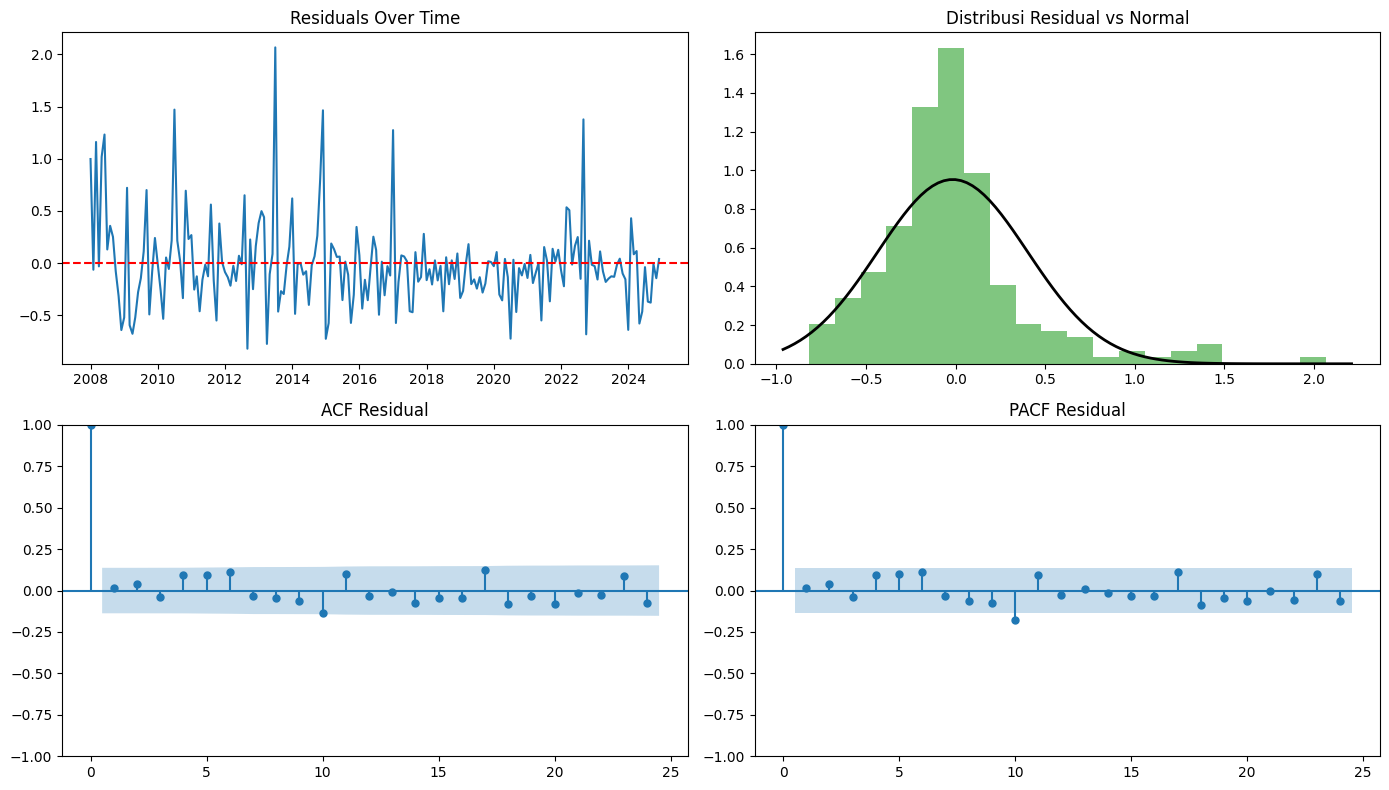

In [11]:
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
import numpy as np

# Mengambil residual dari model optimal
residuals = stepwise_model.resid()

# 1. Uji Ljung-Box untuk Autokorelasi Residual (pada lag 12 dan 24)
lb_test = sm.stats.acorr_ljungbox(residuals, lags=[12, 24], return_df=True)
print("=== UJI LJUNG-BOX RESIDUAL ===")
print(lb_test)
print("(Catatan: P-value > 0.05 menunjukkan residual bersifat white noise / aman)\n")

# 2. Uji Normalitas Jarque-Bera
jb_stat, jb_pvalue = stats.jarque_bera(residuals)
print(f"=== UJI JARQUE-BERA NORMALITAS ===")
print(f"JB Statistic = {jb_stat:.4f}, p-value = {jb_pvalue:.4f}\n")

# 3. Plot Diagnostik Residual
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(residuals, color='tab:blue')
axes[0, 0].set_title("Residuals Over Time")
axes[0, 0].axhline(0, color='red', linestyle='--')

axes[0, 1].hist(residuals, bins=20, density=True, alpha=0.6, color='tab:green')
xmin, xmax = axes[0, 1].get_xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, np.mean(residuals), np.std(residuals))
axes[0, 1].plot(x, p, 'k', linewidth=2)
axes[0, 1].set_title("Distribusi Residual vs Normal")

sm.graphics.tsa.plot_acf(residuals, lags=24, ax=axes[1, 0], alpha=0.05)
axes[1, 0].set_title("ACF Residual")

sm.graphics.tsa.plot_pacf(residuals, lags=24, ax=axes[1, 1], method='yw', alpha=0.05)
axes[1, 1].set_title("PACF Residual")

plt.tight_layout()
plt.show()

Training set: 180 observasi | Testing set: 24 observasi

=== EVALUASI OUT-OF-SAMPLE (24 BULAN TERAKHIR) ===
RMSE : 0.2650
MAE  : 0.1945


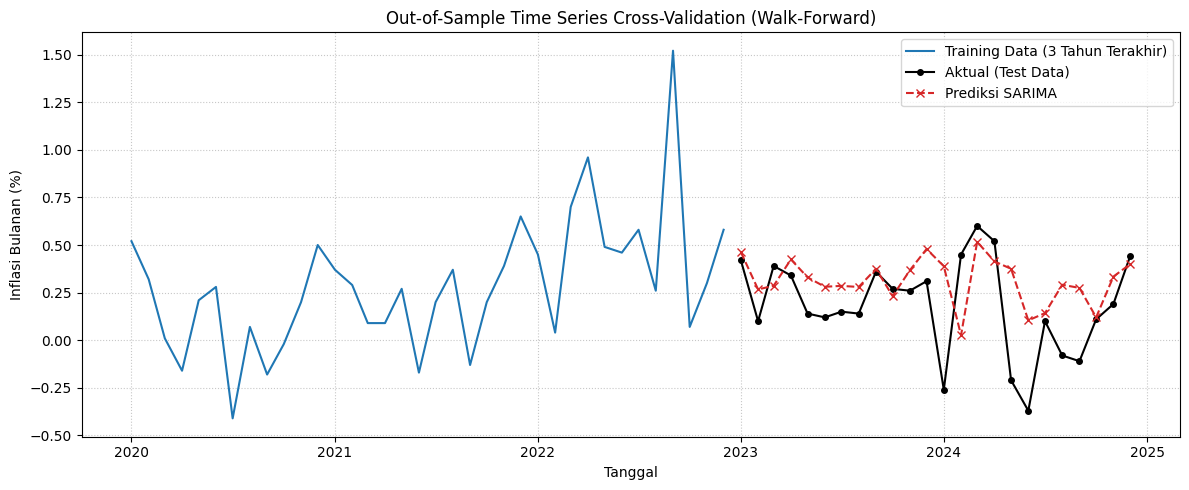

In [12]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# Tentukan jumlah data testing di akhir (misal 24 bulan / 2 tahun terakhir)
n_test = 24
train = series.iloc[:-n_test]
test = series.iloc[-n_test:]

history = list(train)
predictions = []

print(f"Training set: {len(train)} observasi | Testing set: {len(test)} observasi")

# Walk-forward validation loop
for t in range(len(test)):
    # Fit ulang model dengan parameter order & seasonal_order terbaik dari auto_arima
    model = pm.ARIMA(order=stepwise_model.order, seasonal_order=stepwise_model.seasonal_order)
    fitted_model = model.fit(history)
    
    # Prediksi 1 langkah ke depan
    yhat = fitted_model.predict(n_periods=1)[0]
    predictions.append(yhat)
    
    # Masukkan nilai aktual ke history untuk iterasi berikutnya
    obs = test.iloc[t]
    history.append(obs)

predictions = pd.Series(predictions, index=test.index)

# Hitung Metrik Evaluasi Out-of-Sample
rmse = root_mean_squared_error(test, predictions)
mae = mean_absolute_error(test, predictions)

print(f"\n=== EVALUASI OUT-OF-SAMPLE (24 BULAN TERAKHIR) ===")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")

# Visualisasi Hasil Prediksi vs Aktual
plt.figure(figsize=(12, 5))
plt.plot(train.index[-36:], train.iloc[-36:], label="Training Data (3 Tahun Terakhir)", color='tab:blue')
plt.plot(test.index, test, label="Aktual (Test Data)", color="black", marker='o', markersize=4)
plt.plot(predictions.index, predictions, label="Prediksi SARIMA", color="tab:red", linestyle='--', marker='x')
plt.title("Out-of-Sample Time Series Cross-Validation (Walk-Forward)")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()